# A5 season types: training and evaluation

Trains the season-type clustering step by step, evaluates it, and saves the outputs the app reads to `data/processed/models/a5/`. The formulas are tested functions in `model/season_types.py` and `model/season_pipeline.py`. `python -m model.build` reruns this notebook to rebuild everything.

Settings and their sources: `config/models.yaml`. Write-up: `docs/model-results.md`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import experiments, season_pipeline
from model import season_types as st
from model.experiments import log_experiments
from model.io import load_tables, write_json
from model.settings import load_model_config

## 1. Load the feature tables and settings

In [4]:
# Load the LGA-year, LGA-month and static feature tables, cut to the A5 years (2000 to
# 2024) in config/models.yaml, and list the seven clustering features.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
sc = cfg.season_types
year, month, static = load_tables(cfg.paths.features_dir, cfg)
features = list(sc.features)
{
    "LGA-years": len(year),
    "LGAs": year["lga"].nunique(),
    "years": f"{year['year'].min()} to {year['year'].max()}",
    "features": features,
}

{'LGA-years': 575,
 'LGAs': 23,
 'years': '2000 to 2024',
 'features': ['a2_onset_doy',
  'a2_cessation_doy',
  'a2_length_days',
  'season_rain_mm',
  'a2_longest_dry_spell_days',
  'a2_dry_spells_10plus',
  'season_power_heat_days']}

## 2. Build the training matrix

Each feature becomes an anomaly against the LGA's own mean, so "late" means late for that LGA. Peak greenness (`ndvi_z`) is kept aside as an independent check, not a clustering input. Kaduna North and South (little cropland) are left out of the fit.

In [5]:
# Turn each feature into a within-LGA anomaly (z against that LGA's own years), so a "late"
# year means late for that LGA. Mark which rows enter the fit: all LGA-years except Kaduna
# North and South, whose cropland is too small; they still get a season type later.
frame = season_pipeline.season_type_frame(year, static, cfg)
x = frame.loc[frame["fit"], features].to_numpy()
frame.loc[frame["fit"], ["lga", "year", *features]].head()

,lga,year,a2_onset_doy,a2_cessation_doy,a2_length_days,season_rain_mm,a2_longest_dry_spell_days,a2_dry_spells_10plus,season_power_heat_days
0,Birnin Gwari,2000,0.161592,0.353923,-0.018226,-0.031081,-1.428669,-1.743560,1.550761
1,Birnin Gwari,2001,-0.636392,-1.016906,0.209597,-0.004081,-0.767248,0.550598,-0.565452
2,Birnin Gwari,2002,-2.132613,0.852407,2.260000,0.636278,-0.105827,0.550598,-0.988695
3,Birnin Gwari,2003,-0.037904,-0.767665,-0.246048,0.772321,-1.097958,-1.743560,-0.650101
4,Birnin Gwari,2004,-1.035385,-1.016906,0.574113,1.506626,-0.436538,0.550598,0.958222


In [6]:
# Check the standardization: every feature should show mean about 0 and sd about 1.
# The anomalies are already standardized within each LGA (mean 0, sd 1), which is the
# standardization the engineering standards ask for before k-means.
pd.DataFrame(x, columns=features).describe().loc[["count", "mean", "std"]].round(2)

,a2_onset_doy,a2_cessation_doy,a2_length_days,season_rain_mm,a2_longest_dry_spell_days,a2_dry_spells_10plus,season_power_heat_days
count,525.00,525.00,525.00,525.00,525.00,525.00,525.00
mean,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00
std,0.98,0.98,0.98,0.98,0.98,0.98,0.98


## 3. Choose k: silhouette, Davies-Bouldin, seed stability and GMM BIC for k = 2 to 6

In [7]:
# Score k = 2 to 6 four ways: silhouette (separation), Davies-Bouldin (compactness),
# stability across random seeds (adjusted Rand index), and Gaussian mixture BIC.
selection = st.score_k(x, sc.k_candidates, sc.n_init, cfg.random_seed, sc.stability_seeds)
selection.round(3)

,k,silhouette,davies_bouldin,seed_ari_min,seed_ari_mean,smallest_cluster_share,gmm_bic
0,2,0.209,1.751,0.992,0.993,0.453,7051.455
1,3,0.197,1.553,1.000,1.000,0.291,7027.356
2,4,0.194,1.615,0.941,0.978,0.183,7051.085
3,5,0.193,1.491,0.872,0.903,0.177,7111.691
4,6,0.198,1.440,0.896,0.943,0.130,7267.577


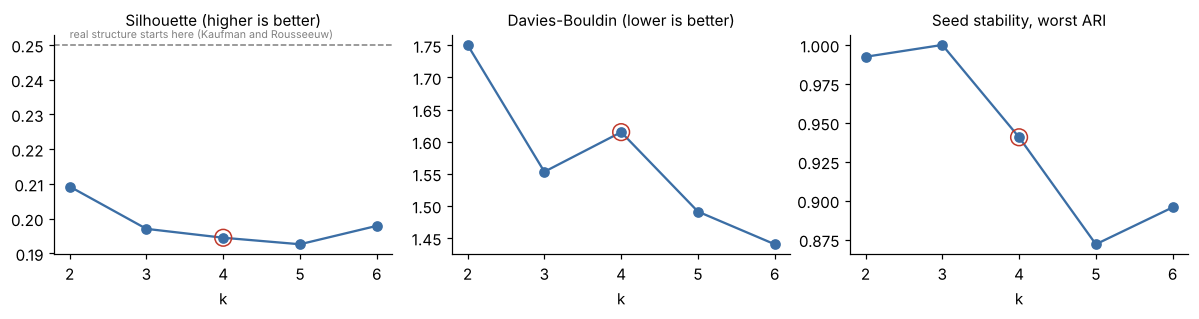

In [8]:
# Plot the k scores. The red circle marks the k set in config (4). The grey line at 0.25
# silhouette is where real cluster structure usually starts.
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
panels = [
    ("silhouette", "Silhouette (higher is better)"),
    ("davies_bouldin", "Davies-Bouldin (lower is better)"),
    ("seed_ari_min", "Seed stability, worst ARI"),
]
for ax, (col, title) in zip(axes, panels, strict=True):
    ax.plot(selection["k"], selection[col], marker="o", color="#3b6ea5")
    chosen = selection["k"] == sc.k
    ax.scatter(
        selection.loc[chosen, "k"],
        selection.loc[chosen, col],
        s=120,
        facecolors="none",
        edgecolors="#c0392b",
        zorder=3,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("k")
axes[0].axhline(0.25, ls="--", color="grey", lw=1)
axes[0].text(
    2, 0.252, "real structure starts here (Kaufman and Rousseeuw)", fontsize=7, color="grey"
)
plt.tight_layout()

Every k scores below 0.25 silhouette: Kaduna seasons form a continuum, not natural groups. k = 4 is within 0.015 of the best and gives the season selector its four scenarios, so the config sets `k: 4`.

## 4. Train K-means

In [9]:
# Train K-means with the chosen k on the anomaly matrix (21 LGAs x 25 years), then name each
# centroid from its strongest anomalies (Typical, Dry spell, Late start, Short and dry).
kmeans = KMeans(n_clusters=sc.k, n_init=sc.n_init, random_state=cfg.random_seed).fit(x)
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=features)
names = st.name_clusters(centroids, sc.name_min_z)
fit_scores = {
    "inertia": round(kmeans.inertia_, 1),
    "silhouette": round(silhouette_score(x, kmeans.labels_), 3),
}
centroids.assign(season_type=[names[i] for i in centroids.index]).set_index("season_type").round(2)

,a2_onset_doy,a2_cessation_doy,a2_length_days,season_rain_mm,a2_longest_dry_spell_days,a2_dry_spells_10plus,season_power_heat_days
season_type,,,,,,,
Dry spell,-0.57,0.50,0.70,0.35,1.05,0.87,0.02
Typical,-0.68,0.09,0.66,0.37,-0.72,-0.72,-0.13
Short and dry,0.68,-0.90,-0.91,-0.83,-0.02,0.17,-0.60
Late start,1.05,0.28,-0.91,-0.03,-0.46,-0.45,0.96


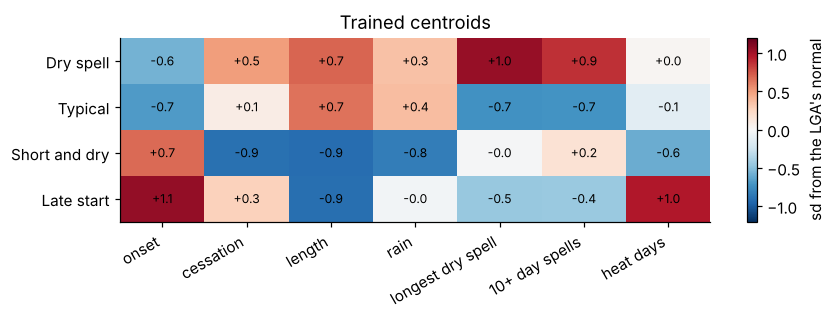

In [10]:
# Draw each trained centroid: how far its average year sits from normal, feature by feature,
# in standard deviations.
fig, ax = plt.subplots(figsize=(8, 3))
labels = [
    "onset",
    "cessation",
    "length",
    "rain",
    "longest dry spell",
    "10+ day spells",
    "heat days",
]
im = ax.imshow(centroids, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(centroids)), [names[i] for i in centroids.index])
for i in range(len(centroids)):
    for j in range(len(features)):
        ax.text(j, i, f"{centroids.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="sd from the LGA's normal")
ax.set_title("Trained centroids")
plt.tight_layout()

## 5. Sanity checks: rerun with 20 seeds, and compare against a Gaussian mixture

In [11]:
# Robustness: refit with 20 seeds and compare labels (ARI); fit a Gaussian mixture and count
# how often it agrees with K-means. Then assign a type to every LGA-year, all 23 LGAs.
seed_labels = [
    KMeans(sc.k, n_init=sc.n_init, random_state=cfg.random_seed + s).fit_predict(x)
    for s in range(sc.stability_seeds)
]
ari = [adjusted_rand_score(seed_labels[0], other) for other in seed_labels[1:]]
gmm = GaussianMixture(sc.k, covariance_type="full", n_init=10, random_state=cfg.random_seed).fit(x)
types = season_pipeline.assign_types(frame, kmeans, names, features, cfg)
fitted = types[~types["low_cropland"]]
{
    "seed ARI min": round(min(ari), 3),
    "seed ARI mean": round(float(np.mean(ari)), 3),
    "GMM BIC at k = 4": round(gmm.bic(x), 1),
    "GMM agrees with K-means": round(float(fitted["gmm_agrees"].mean()), 3),
}

{'seed ARI min': 0.941,
 'seed ARI mean': 0.978,
 'GMM BIC at k = 4': 7051.1,
 'GMM agrees with K-means': 0.585}

## 6. Evaluate: do bad greenness years land in a stress type?

Greenness was not a clustering input, so this check is independent. The permutation test moves whole years' labels, because LGAs in the same year share weather.

In [12]:
# Independent check: share of years with stressed greenness in each type, and a permutation
# test that shuffles whole years (LGAs in one year share weather, so rows are not
# independent). Greenness was never a clustering input.
stressed = fitted.groupby("season_type")["stressed"].mean()
p_value = st.year_block_p(
    fitted[["year", "lga", "season_type", "stressed"]], sc.permutation_runs, cfg.random_seed
)
{
    "share stressed by type": stressed.round(3).to_dict(),
    "year-block permutation p": round(p_value, 3),
}

{'share stressed by type': {'Dry spell': 0.295,
  'Late start': 0.229,
  'Short and dry': 0.383,
  'Typical': 0.243},
 'year-block permutation p': 0.379}

,year,statewide_type,mean_ndvi_z
14,2014,Dry spell,-1.014556
7,2007,Short and dry,-0.919844
8,2008,Short and dry,-0.899886
17,2017,Short and dry,-0.760654


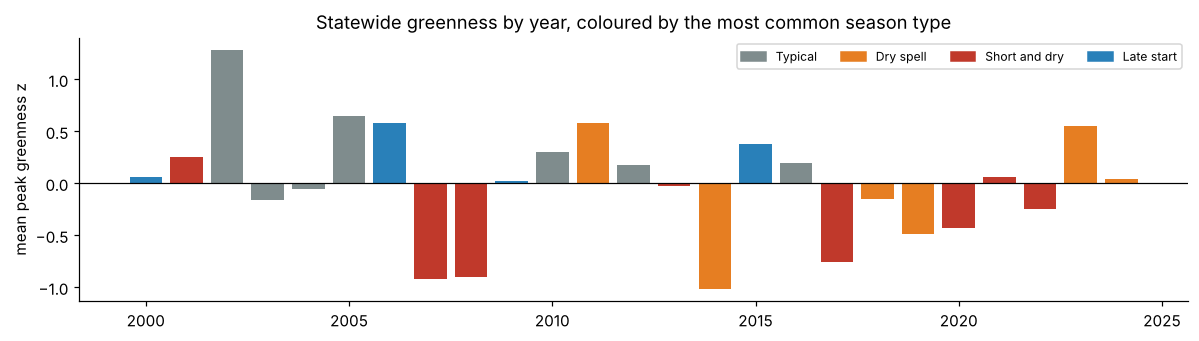

In [13]:
# Statewide view per year: the most common type across LGAs and the mean greenness anomaly.
# The table lists the four worst greenness years.
yearly = (
    fitted.groupby("year")
    .agg(
        statewide_type=("season_type", lambda s: s.mode().iloc[0]),
        mean_ndvi_z=("ndvi_z", "mean"),
    )
    .reset_index()
)
colours = {
    "Typical": "#7f8c8d",
    "Dry spell": "#e67e22",
    "Short and dry": "#c0392b",
    "Late start": "#2980b9",
}
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(yearly["year"], yearly["mean_ndvi_z"], color=yearly["statewide_type"].map(colours))
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("mean peak greenness z")
ax.set_title("Statewide greenness by year, coloured by the most common season type")
ax.legend(
    [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()],
    colours.keys(),
    fontsize=8,
    ncols=4,
)
plt.tight_layout()
yearly.sort_values("mean_ndvi_z").head(4)

**Reading.** The four worst greenness years all fall in the two dry types (2014 Dry spell; 2007, 2008 and 2017 Short and dry), which fits. But with 25 years the gap between types could be chance (p above 0.3). Cards present season types as weather scenarios; greenness by type goes to Learn as weak evidence.

## 7. Monthly profiles: one LGA in detail, then all 23 LGAs

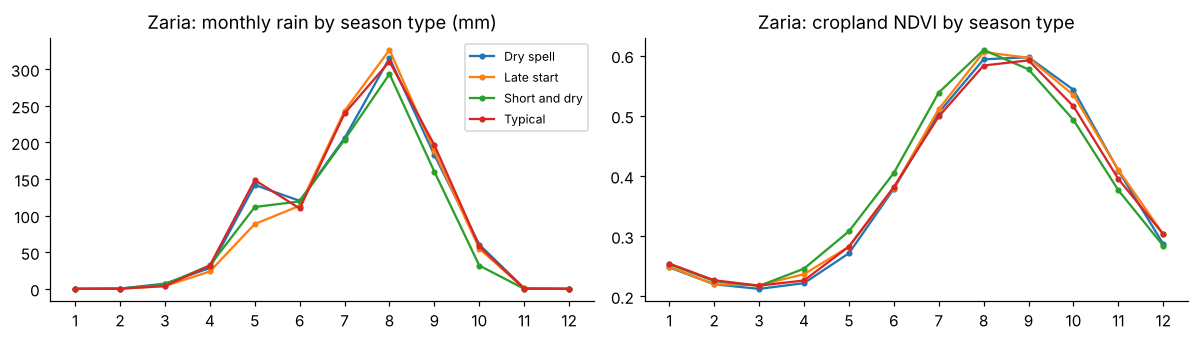

In [14]:
# Worked example for the season strip: monthly rain and cropland NDVI by type for Zaria.
# Profiles are computed for every LGA; the next cell shows all 23.
profiles = st.monthly_profiles(month, types, season_pipeline.PROFILE_COLUMNS, sc.profile_min_years)
lga = "Zaria"
p = profiles[profiles["lga"] == lga]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for season_type, g in p.groupby("season_type"):
    axes[0].plot(g["month"], g["rain_mm"].clip(lower=0), marker="o", ms=3, label=season_type)
    axes[1].plot(g["month"], g["ndvi_crop_sg"], marker="o", ms=3, label=season_type)
axes[0].set_title(f"{lga}: monthly rain by season type (mm)")
axes[1].set_title(f"{lga}: cropland NDVI by season type")
for ax in axes:
    ax.set_xticks(range(1, 13))
axes[0].legend(fontsize=8)
plt.tight_layout()

season_type,Dry spell,Late start,Short and dry,Typical
lga,,,,
Birnin Gwari,1194.0,1133.0,1029.0,1229.0
Chikun,1308.0,1247.0,1163.0,1278.0
Giwa,1114.0,1074.0,978.0,1090.0
Igabi,1227.0,1160.0,1085.0,1201.0
Ikara,1040.0,982.0,921.0,1003.0
Jaba,1511.0,1511.0,1381.0,1497.0
Jema'a,1444.0,1476.0,1354.0,1430.0
Kachia,1525.0,1430.0,1343.0,1463.0
Kaduna North,1219.0,1139.0,1068.0,1193.0


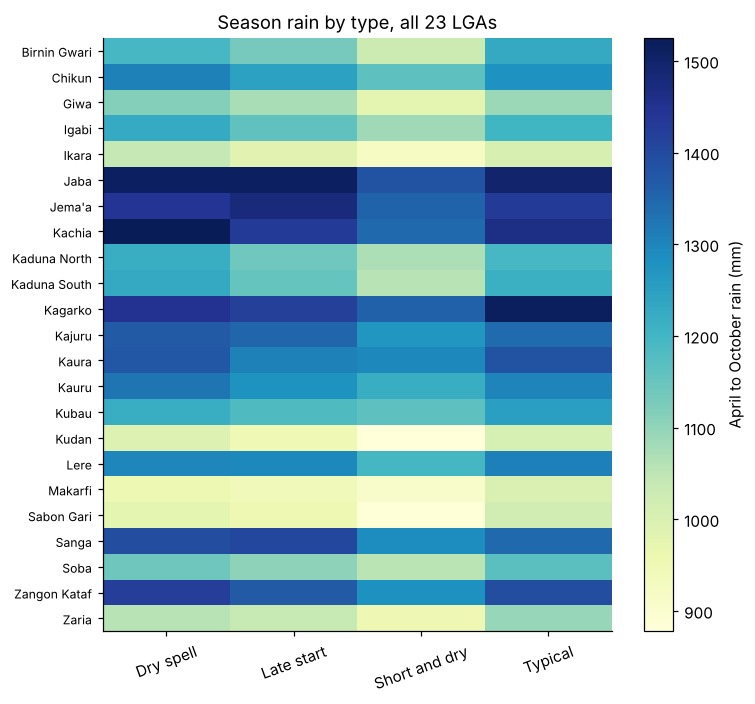

In [15]:
# All 23 LGAs: April to October rain under each season type. Blank cells are LGA-type
# pairs with too few years to profile (config: profile_min_years).
season_rain = (
    profiles[profiles["month"].between(4, 10)]
    .groupby(["lga", "season_type"])["rain_mm"]
    .sum()
    .unstack()
)
fig, ax = plt.subplots(figsize=(7, 6.5))
im = ax.imshow(season_rain, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(season_rain.shape[1]), season_rain.columns, rotation=20)
ax.set_yticks(range(season_rain.shape[0]), season_rain.index, fontsize=8)
fig.colorbar(im, label="April to October rain (mm)")
ax.set_title("Season rain by type, all 23 LGAs")
plt.tight_layout()
season_rain.round(0)

## 8. Save the outputs and log the run

These files are what the app and A6 and A9 read. `python -m model.build` reruns this notebook top to bottom to rebuild them.

In [16]:
# Write the A5 outputs the app, A6 and A9 read, then append this run to
# docs/experiments.csv (one row per date, model and split).
out = cfg.paths.output_dir / "a5"
out.mkdir(parents=True, exist_ok=True)
season_pipeline.write_tables(types, centroids, names, out)
season_pipeline.write_profiles_and_selection(types, month, selection, cfg, out)
summary = season_pipeline.summarise(selection, types, sc.k, p_value)
write_json(summary, out / "a5_summary.json")
log_experiments(cfg.paths.experiment_log, [experiments.a5_row(summary, cfg, experiments.today())])
sorted(p.name for p in out.iterdir())

['a5_centroids.csv',
 'a5_lga_type_share.csv',
 'a5_lga_year_types.csv',
 'a5_model_selection.csv',
 'a5_monthly_profiles.csv',
 'a5_summary.json',
 'a5_year_summary.csv']